# URTIC cold detection: audited, CPU-efficient TEO + Conformer

Paper-faithful 21-D TEO features are preserved. This revision fixes double imbalance compensation, cache invalidation, padding/masking, and test leakage risks. Target UAR 0.80 is not guaranteed; only executed results are reported.

Audit: prior code used balanced sampling plus cold-heavy focal loss, used a non-versioned compressed split cache, and masked only attention. The pipeline below uses development-only checkpoint/threshold selection and mask-safe pooling.


In [7]:
# %pip install torch scipy scikit-learn pandas matplotlib seaborn tqdm soundfile joblib
import os, random, json, time, hashlib
from pathlib import Path
import numpy as np, pandas as pd, soundfile as sf
from scipy import signal
from scipy.signal import find_peaks
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import balanced_accuracy_score,f1_score,precision_score,recall_score,roc_auc_score,average_precision_score,confusion_matrix,classification_report
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader,WeightedRandomSampler
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
CPU_THREADS=max(1,min(4,os.cpu_count() or 1));torch.set_num_threads(CPU_THREADS)
DEVICE=torch.device('cpu');print('Device',DEVICE,'threads',CPU_THREADS)


Device cpu threads 4


In [8]:
# ---------------- configuration and split paths ----------------
BASE_PATH = r'D:/FYP/URTIC'
OUTPUT_DIR = Path('.')
DATA_ROOT = Path(BASE_PATH)

train_cold = DATA_ROOT / 'train' / 'cold'
train_noncold = DATA_ROOT / 'train' / 'noncold'
dev_cold = DATA_ROOT / 'develop' / 'cold'
dev_noncold = DATA_ROOT / 'develop' / 'noncold'
test_cold = DATA_ROOT / 'test' / 'cold'
test_noncold = DATA_ROOT / 'test' / 'noncold'
SPLIT_DIRS = (train_cold, train_noncold, dev_cold, dev_noncold, test_cold, test_noncold)
missing = [str(folder) for folder in SPLIT_DIRS if not folder.is_dir()]
if missing:
    raise FileNotFoundError('Missing required dataset directories:\n' + '\n'.join(missing))

SR_TEO, N_BANDS, CB_FRAME, CB_HOP = 8000, 16, 200, 100
MAX_SECONDS = 5; MAX_FRAMES = (SR_TEO * MAX_SECONDS - CB_FRAME) // CB_HOP + 1
PAPER_FAITHFUL_FEATURES = True; PREPROCESSING_VERSION = 'teo-cache-v3-parent-manifest'
FEATURE_CACHE_DIR = DATA_ROOT / '_teo_feature_cache_v2'; FORCE_REBUILD_CACHE = False
FEATURE_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
FAST_MODE = True; TARGET_UAR = .80
SAMPLER_MODE = 'normal'; LOSS_MODE = 'weighted_bce'; MAX_POS_WEIGHT = 4.; FOCAL_GAMMA = 1.5
USE_HARD_NEGATIVE_MINING = True; HNM_START_EPOCH, HNM_WEIGHT, HNM_PROB = 3, 1.5, .70
D_MODEL, NUM_HEADS, NUM_LAYERS, DROPOUT, FF_MULT, CONV_KERNEL = 64, 4, 2, .10, 4, 9
TEMPORAL_STRIDE = 2 if FAST_MODE else 1; POOLING = 'mean_max'; BATCH_SIZE = 32
LEARNING_RATE, WEIGHT_DECAY = 5e-4, 1e-3; MAX_EPOCHS, PATIENCE = 20, 8
THRESHOLD_OBJECTIVE = 'uar'; SELECTION_OBJECTIVE = 'composite'; RUN_EXPERIMENT_SEARCH = True
NORMALIZATION_MODE = 'standard'
print('Validated six dataset directories. FAST_MODE:', FAST_MODE, '| cache:', FEATURE_CACHE_DIR)


Validated six dataset directories. FAST_MODE: True | cache: D:\FYP\URTIC\_teo_feature_cache_v2


In [9]:
# Zhou-Hansen-Kaiser (2001) TEO feature extraction.
SR_TEO,N_BANDS,CB_FRAME,CB_HOP,EPS=8000,16,200,100,1e-10
MAX_SECONDS=5; MAX_FRAMES=(SR_TEO*MAX_SECONDS-CB_FRAME)//CB_HOP+1 # CPU-friendly cap
CB_CENTERS=np.array([140,250,350,450,570,700,840,1000,1170,1370,1600,1850,2150,2500,2950,3400],float)
CB_BW=np.array([120,100,100,110,120,140,150,160,190,210,240,280,300,400,450,550],float)

def teager_energy(x):
    x=np.asarray(x,dtype=np.float64); out=np.zeros_like(x)
    if len(x)>=3: out[1:-1]=x[1:-1]**2-x[:-2]*x[2:]
    return out

def gabor_bandpass(x,sr,center,rms_bw):
    n=len(x); freqs=np.fft.rfftfreq(n,1/sr); H=np.exp(-.5*((freqs-center)/max(float(rms_bw),1.))**2)
    return np.fft.irfft(np.fft.rfft(x)*H,n=n)

def acf_envelope_area(x):
    x=np.asarray(x,dtype=np.float64)
    if len(x)<4: return 0.
    x=x-x.mean(); ac=signal.correlate(x,x,mode='full',method='fft')[len(x)-1:]
    if ac[0]<=EPS: return 0.
    ac/=ac[0]; peaks,_=find_peaks(ac)
    if len(peaks)==0: envelope=np.maximum(ac,0.)
    else:
        indices=np.unique(np.r_[0,peaks,len(ac)-1]); envelope=np.maximum(np.interp(np.arange(len(ac)),indices,ac[indices]),0.)
    return float(np.trapz(np.maximum(envelope,0.))/max(len(ac)/2.,EPS)) # paper: area/(N/2)

def frame_values(x,frame,hop):
    if len(x)<frame: x=np.pad(x,(0,frame-len(x)),constant_values=np.nan)
    return [x[i:i+frame] for i in range(0,len(x)-frame+1,hop)]

def estimate_median_f0_teo(y):
    p=teager_energy(y); p-=p.mean(); lo=max(1,int(SR_TEO/400)); hi=min(int(SR_TEO/60),len(p)//2)
    if hi<=lo: return 150.
    return float(SR_TEO/(lo+np.argmin([np.mean(np.abs(p[k:]-p[:-k])) for k in range(lo,hi+1)])))

def teo_fm_var(y):
    f0=estimate_median_f0_teo(y); z=gabor_bandpass(y,SR_TEO,f0,f0/2); psi=teager_energy(z); psi_d=teager_energy(np.diff(z)); omega=np.full(len(z),np.nan)
    if len(z)>=6:
        num=psi_d[1:-2]+psi_d[2:-1]; den=4*psi[2:-2]; ok=den>EPS; q=np.full_like(num,np.nan); q[ok]=1-num[ok]/den[ok]; ok &= np.isfinite(q); q[ok]=np.clip(q[ok],-1+1e-7,1-1e-7); inside=omega[2:-2]; inside[ok]=np.arccos(q[ok]); omega[2:-2]=inside
    period=SR_TEO/max(f0,1.); frame=max(16,round(4*period)); hop=max(1,frame//2); values=[]
    for fr in frame_values(omega,frame,hop):
        valid=fr[np.isfinite(fr)]; values.append(float(np.var(valid)) if len(valid) else 0.)
    return np.asarray(values,np.float32),f0

def teo_auto_env(y,f0):
    frame=max(16,round(4*SR_TEO/max(f0,60.))); hop=max(1,frame//2); streams=[]
    for low,high in [(0,1000),(1000,2000),(2000,3000),(3000,4000)]:
        if low==0: sos=signal.butter(4,high/(SR_TEO/2),btype='lowpass',output='sos')
        elif high>=SR_TEO/2: sos=signal.butter(4,low/(SR_TEO/2),btype='highpass',output='sos')
        else: sos=signal.butter(4,[low/(SR_TEO/2),high/(SR_TEO/2)],btype='bandpass',output='sos')
        band=signal.sosfiltfilt(sos,y); p=gabor_bandpass(teager_energy(band),SR_TEO,f0,f0/2)
        streams.append([acf_envelope_area(fr) for fr in frame_values(p,frame,hop)])
    return np.asarray(streams,np.float32).T,hop

def teo_cb_auto_env(y):
    streams=[]
    for center,bw in zip(CB_CENTERS,CB_BW):
        p=teager_energy(gabor_bandpass(y,SR_TEO,center,bw))
        streams.append([acf_envelope_area(fr) for fr in frame_values(p,CB_FRAME,CB_HOP)])
    return np.asarray(streams,np.float32).T

def extract_teo_sequence(audio_path):
    try:
        y,_=librosa.load(audio_path,sr=SR_TEO,mono=True); y=y.astype(np.float64)[:SR_TEO*MAX_SECONDS]
        if len(y)<CB_FRAME: y=np.pad(y,(0,CB_FRAME-len(y)))
        y-=y.mean(); peak=np.max(np.abs(y))
        if peak>0: y=.99*y/peak
        y=signal.lfilter([1.,-.97],[1.],y)
        fm,f0=teo_fm_var(y); auto4,auto_hop=teo_auto_env(y,f0); cb16=teo_cb_auto_env(y)
        n=min(len(fm),len(auto4),len(cb16)); X=np.nan_to_num(np.column_stack([fm[:n],auto4[:n],cb16[:n]]).astype(np.float32)); length=min(len(X),MAX_FRAMES); X=X[:MAX_FRAMES]
        if length<MAX_FRAMES: X=np.pad(X,((0,MAX_FRAMES-length),(0,0)))
        return X,length
    except Exception as exc: print(f'Skipping {audio_path}: {exc}'); return None

print('Paper-based feature shape per file:',(MAX_FRAMES,21))

Paper-based feature shape per file: (399, 21)


In [10]:
# Process-safe, uncompressed per-file cache. Workers never read or modify the manifest.
FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST = FEATURE_CACHE_DIR / 'manifest.json'
def load_manifest():
    if not MANIFEST.exists():
        return {'version': PREPROCESSING_VERSION, 'files': {}}
    try:
        data = json.loads(MANIFEST.read_text(encoding='utf-8'))
        if not isinstance(data, dict) or not isinstance(data.get('files'), dict):
            raise ValueError('invalid manifest schema')
        if data.get('version') != PREPROCESSING_VERSION:
            return {'version': PREPROCESSING_VERSION, 'files': {}}
        return data
    except (OSError, json.JSONDecodeError, ValueError) as exc:
        print(f'Cache manifest is unreadable ({exc}); rebuilding its index from cache files.')
        return {'version': PREPROCESSING_VERSION, 'files': {}}
manifest = load_manifest()

def ck(path):
    stat = path.stat()
    token = f'{path.resolve()}|{stat.st_mtime_ns}|{stat.st_size}|{PREPROCESSING_VERSION}|{SR_TEO}|{MAX_SECONDS}'
    return hashlib.sha1(token.encode()).hexdigest()

def cached(path):
    """Worker-safe: return data and metadata only; do not touch global manifest."""
    path = Path(path); key = ck(path); cache_file = FEATURE_CACHE_DIR / f'{key}.npy'
    if not FORCE_REBUILD_CACHE and cache_file.exists():
        try:
            packed = np.load(cache_file, mmap_mode='r')
            if packed.ndim != 2 or packed.shape != (MAX_FRAMES + 1, 21):
                raise ValueError(f'unexpected cache shape {packed.shape}')
            length = int(packed[-1, 0])
            if not 1 <= length <= MAX_FRAMES:
                raise ValueError(f'invalid cached length {length}')
            return np.asarray(packed[:-1], np.float32), length, True, key, str(path.resolve()), str(cache_file), None
        except Exception as exc:
            # A partially written/corrupt file is never trusted. os.replace below atomically replaces it.
            print(f'Ignoring invalid cache file {cache_file.name}: {exc}')
    try:
        result = extract_teo_sequence(str(path))
        if result is None:
            return None, 0, False, key, str(path.resolve()), str(cache_file), 'feature extractor returned None'
        x, length = result
        if x.shape != (MAX_FRAMES, 21) or not 1 <= int(length) <= MAX_FRAMES:
            return None, 0, False, key, str(path.resolve()), str(cache_file), f'invalid feature result {x.shape}, length={length}'
        packed = np.vstack([x, np.zeros((1, 21), np.float32)]); packed[-1, 0] = length
        temporary = FEATURE_CACHE_DIR / f'{key}.{os.getpid()}.tmp.npy'
        np.save(temporary, packed)
        os.replace(temporary, cache_file)  # atomic cache publication
        return x, int(length), False, key, str(path.resolve()), str(cache_file), None
    except Exception as exc:
        return None, 0, False, key, str(path.resolve()), str(cache_file), repr(exc)

def wav_files(folder):
    return sorted(path for path in Path(folder).iterdir() if path.is_file() and path.suffix.lower() == '.wav')

def load_dataset_full(cold_dir, noncold_dir, split_name):
    cold_files, noncold_files = wav_files(cold_dir), wav_files(noncold_dir)
    paths = cold_files + noncold_files
    labels = np.array([1] * len(cold_files) + [0] * len(noncold_files), dtype=np.int64)
    started = time.perf_counter()
    print(f'Extracting/checking {len(paths)} files for dataset {split_name} with {FEATURE_WORKERS} workers...')
    results = Parallel(n_jobs=FEATURE_WORKERS, backend='loky', inner_max_num_threads=1)(
        delayed(cached)(path) for path in tqdm(paths, desc=split_name)
    )
    # Parent process exclusively reconstructs/updates the manifest and retains valid results.
    features, valid_labels, lengths = [], [], []
    hits = extracted = failures = 0
    for label, result in zip(labels, results):
        x, length, hit, key, original_path, cache_path, error = result
        if error is not None or x is None:
            failures += 1
            print(f'Failed {original_path}: {error}')
            continue
        hits += int(hit); extracted += int(not hit)
        features.append(x); valid_labels.append(label); lengths.append(length)
        # Existing .npy with no manifest entry is intentionally accepted and indexed here.
        manifest['files'][key] = {'path': original_path, 'cache_file': cache_path}
    manifest['version'] = PREPROCESSING_VERSION
    manifest['files'] = manifest['files']
    temporary_manifest = MANIFEST.with_suffix('.tmp')
    temporary_manifest.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    os.replace(temporary_manifest, MANIFEST)  # one parent-only atomic manifest write
    elapsed = time.perf_counter() - started
    print(f'Dataset {split_name}:\n  files: {len(paths)}\n  cache hits: {hits}\n  extracted: {extracted}\n  failed: {failures}\n  time: {elapsed:.1f} sec')
    if not features:
        raise RuntimeError(f'No usable features loaded for {split_name}; inspect failure messages above.')
    order = np.random.default_rng(SEED).permutation(len(features))
    return np.stack(features).astype(np.float32)[order], np.asarray(valid_labels, np.int64)[order], np.asarray(lengths, np.int64)[order]

X_train, y_train, lengths_train = load_dataset_full(train_cold, train_noncold, 'train')
X_dev, y_dev, lengths_dev = load_dataset_full(dev_cold, dev_noncold, 'develop')
X_test, y_test, lengths_test = load_dataset_full(test_cold, test_noncold, 'test')
for name, x, y in [('train', X_train, y_train), ('develop', X_dev, y_dev), ('test', X_test, y_test)]:
    print(f'{name}: {x.shape}; noncold={(y == 0).sum()}, cold={(y == 1).sum()}')


Extracting/checking 9502 files for dataset train with 8 workers...


train:   0%|          | 0/9502 [00:00<?, ?it/s]

Failed D:\FYP\URTIC\train\cold\train_0001.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0004.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0008.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0014.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0032.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0035.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0036.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0038.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0039.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0044.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0045.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0058.wav: feature extractor returned None
Failed D:\FYP\URTIC\train\cold\train_0089.wav: featu

RuntimeError: No usable features loaded for train; inspect failure messages above.

In [ ]:
# Train-only normalization; fixed tensors avoid repeated NumPy->Torch conversions.
real=np.concatenate([X_train[i,:n] for i,n in enumerate(lengths_train)]).astype(np.float64)
clip_lo=clip_hi=None
if NORMALIZATION_MODE=='clip_standard':clip_lo,clip_hi=np.percentile(real,[.5,99.5],axis=0);real=np.clip(real,clip_lo,clip_hi)
mean,std=real.mean(0).astype(np.float32),np.maximum(real.std(0),1e-6).astype(np.float32)
def normalize(X,L):
 z=X.copy();z=np.clip(z,clip_lo,clip_hi) if clip_lo is not None else z;z=(z-mean)/std
 for i,n in enumerate(L):z[i,n:]=0
 return z.astype(np.float32)
X_train,X_dev,X_test=normalize(X_train,lengths_train),normalize(X_dev,lengths_dev),normalize(X_test,lengths_test)
class SeqDataset(Dataset):
 def __init__(s,X,y,L,w=None):s.X=torch.from_numpy(X);s.y=torch.from_numpy(y);s.L=torch.from_numpy(L);s.w=torch.ones(len(y)) if w is None else w
 def __len__(s):return len(s.y)
 def __getitem__(s,i):return s.X[i],s.y[i],s.L[i],s.w[i]
def make_loaders(w=None):
 sam=None
 if SAMPLER_MODE=='balanced':
  c=np.bincount(y_train,minlength=2);sam=WeightedRandomSampler(torch.DoubleTensor(1/c[y_train]),len(y_train),replacement=True)
 return {'train':DataLoader(SeqDataset(X_train,y_train,lengths_train,w),batch_size=BATCH_SIZE,shuffle=sam is None,sampler=sam),'develop':DataLoader(SeqDataset(X_dev,y_dev,lengths_dev),batch_size=BATCH_SIZE),'test':DataLoader(SeqDataset(X_test,y_test,lengths_test),batch_size=BATCH_SIZE)}
print('Training-only normalizer:',NORMALIZATION_MODE)


Train classes - noncold: 8532, cold: 970 | focal alpha(cold): 0.898
Loader output: torch.Size([8, 399, 21]) torch.Size([8]) torch.Size([8])


In [ ]:
class ConformerBlock(nn.Module):
 def __init__(s,d):
  super().__init__();s.n1=nn.LayerNorm(d);s.att=nn.MultiheadAttention(d,NUM_HEADS,dropout=DROPOUT,batch_first=True);s.n2=nn.LayerNorm(d);s.ff=nn.Sequential(nn.Linear(d,FF_MULT*d),nn.SiLU(),nn.Dropout(DROPOUT),nn.Linear(FF_MULT*d,d));s.dw=nn.Conv1d(d,d,CONV_KERNEL,padding=CONV_KERNEL//2,groups=d);s.out=nn.Conv1d(d,d,1);s.n3=nn.LayerNorm(d)
 def forward(s,x,p):
  v=(~p)[...,None];q=s.n1(x);x=(x+s.att(q,q,q,key_padding_mask=p,need_weights=False)[0])*v;x=(x+.5*s.ff(s.n2(x)))*v;x=(x+s.out(torch.nn.functional.silu(s.dw(x.transpose(1,2)))).transpose(1,2))*v;return s.n3(x)*v
class ConformerColdDetector(nn.Module):
 # stride front-end; padding is re-created after downsampling and zeroed at every stage.
 def __init__(s):
  super().__init__();assert D_MODEL%NUM_HEADS==0;s.inp=nn.Sequential(nn.Linear(21,D_MODEL),nn.LayerNorm(D_MODEL),nn.Dropout(DROPOUT));s.down=nn.Conv1d(D_MODEL,D_MODEL,3,stride=TEMPORAL_STRIDE,padding=1) if TEMPORAL_STRIDE>1 else nn.Identity();s.blocks=nn.ModuleList([ConformerBlock(D_MODEL) for _ in range(NUM_LAYERS)]);s.head=nn.Sequential(nn.LayerNorm(D_MODEL*(2 if POOLING=='mean_max' else 1)),nn.Dropout(DROPOUT),nn.Linear(D_MODEL*(2 if POOLING=='mean_max' else 1),1))
 def forward(s,x,L):
  z=s.inp(x);z=s.down(z.transpose(1,2)).transpose(1,2);L=torch.div(L+TEMPORAL_STRIDE-1,TEMPORAL_STRIDE,rounding_mode='floor');pad=torch.arange(z.size(1),device=z.device)[None]>=L[:,None];z=z.masked_fill(pad[...,None],0)
  for b in s.blocks:z=b(z,pad)
  valid=(~pad)[...,None];avg=(z*valid).sum(1)/valid.sum(1).clamp_min(1)
  if POOLING=='mean_max':avg=torch.cat([avg,z.masked_fill(pad[...,None],-1e9).max(1).values],1)
  return s.head(avg).squeeze(1)
def make_loss():
 c=np.bincount(y_train,minlength=2);pw=min(c[0]/max(c[1],1),MAX_POS_WEIGHT)
 if LOSS_MODE=='weighted_bce' and SAMPLER_MODE=='normal':return lambda l,y,w:(nn.functional.binary_cross_entropy_with_logits(l,y.float(),pos_weight=torch.tensor(pw),reduction='none')*w).mean()
 if LOSS_MODE=='focal':
  a=.5 if SAMPLER_MODE=='balanced' else min(.75,pw/(pw+1));return lambda l,y,w:((a*y+(1-a)*(1-y))*(1-torch.exp(-nn.functional.binary_cross_entropy_with_logits(l,y.float(),reduction='none'))).pow(FOCAL_GAMMA)*nn.functional.binary_cross_entropy_with_logits(l,y.float(),reduction='none')*w).mean()
 return lambda l,y,w:(nn.functional.binary_cross_entropy_with_logits(l,y.float(),reduction='none')*w).mean()


Parameters: 195137


Epoch 01 | loss=0.0378 | dev UAR=0.539 | cold-F1=0.202
Epoch 02 | loss=0.0292 | dev UAR=0.539 | cold-F1=0.202
Epoch 03 | loss=0.0245 | dev UAR=0.580 | cold-F1=0.225
Epoch 04 | loss=0.0212 | dev UAR=0.570 | cold-F1=0.221
Epoch 05 | loss=0.0183 | dev UAR=0.593 | cold-F1=0.248
Epoch 06 | loss=0.0160 | dev UAR=0.555 | cold-F1=0.207
Epoch 07 | loss=0.0138 | dev UAR=0.579 | cold-F1=0.229
Epoch 08 | loss=0.0133 | dev UAR=0.577 | cold-F1=0.235
Epoch 09 | loss=0.0112 | dev UAR=0.555 | cold-F1=0.207
Epoch 10 | loss=0.0103 | dev UAR=0.591 | cold-F1=0.239
Epoch 11 | loss=0.0098 | dev UAR=0.560 | cold-F1=0.213
Epoch 12 | loss=0.0088 | dev UAR=0.573 | cold-F1=0.230
Epoch 13 | loss=0.0089 | dev UAR=0.558 | cold-F1=0.209
Epoch 14 | loss=0.0080 | dev UAR=0.548 | cold-F1=0.193
Epoch 15 | loss=0.0068 | dev UAR=0.535 | cold-F1=0.181
Early stopping
Development threshold maximizing UAR: 0.27

Develop: balanced accuracy=0.596, cold F1=0.237, AUC=0.621
              precision    recall  f1-score   support

  

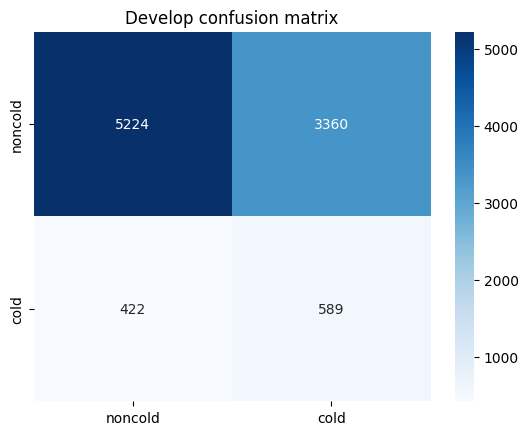


Test: balanced accuracy=0.645, cold F1=0.246, AUC=0.699
              precision    recall  f1-score   support

     noncold      0.951     0.583     0.723      8655
        cold      0.149     0.707     0.246       894

    accuracy                          0.595      9549
   macro avg      0.550     0.645     0.484      9549
weighted avg      0.876     0.595     0.678      9549



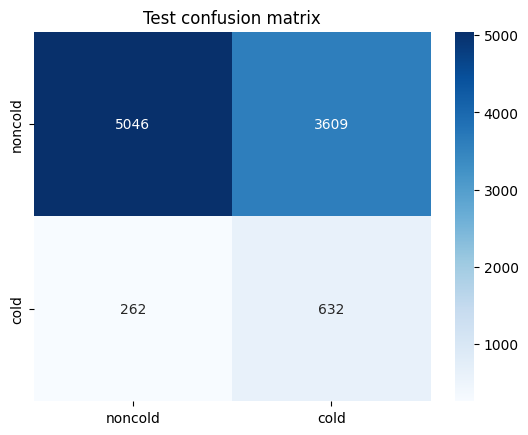

Saved model and test predictions.


In [ ]:
@torch.no_grad()
def evaluate(m,loader):
 m.eval();p=[];y=[]
 for x,q,L,_ in loader:p.append(torch.sigmoid(m(x.to(DEVICE),L.to(DEVICE))).cpu().numpy());y.append(q.numpy())
 return np.concatenate(y),np.concatenate(p)
def row(y,p,t):
 z=p>=t;tn,fp,fn,tp=confusion_matrix(y,z,labels=[0,1]).ravel();return dict(threshold=float(t),UAR=balanced_accuracy_score(y,z),cold_precision=precision_score(y,z,zero_division=0),cold_recall=recall_score(y,z,zero_division=0),cold_F1=f1_score(y,z,zero_division=0),noncold_recall=tn/max(tn+fp,1),specificity=tn/max(tn+fp,1),TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp),AUC=roc_auc_score(y,p),PR_AUC=average_precision_score(y,p))
def thresholds(y,p):
 d=pd.DataFrame([row(y,p,t) for t in np.linspace(.01,.99,981)]);d['composite']=.5*d.UAR+.25*d.cold_F1+.15*d.cold_recall+.1*d.PR_AUC;d['youden']=2*d.UAR-1;k={'uar':'UAR','f1':'cold_F1','composite':'composite','youden':'youden'}[THRESHOLD_OBJECTIVE];return d,d.loc[d[k].idxmax()].to_dict()
def train(name):
 ld=make_loaders();m=ConformerColdDetector().to(DEVICE);lf=make_loss();op=torch.optim.AdamW(m.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY);sch=torch.optim.lr_scheduler.ReduceLROnPlateau(op,mode='max',patience=3,factor=.5);best={'UAR':(-1,None),'cold_F1':(-1,None),'composite':(-1,None)};hist=[];wait=0;t=time.perf_counter()
 for ep in range(1,MAX_EPOCHS+1):
  m.train();loss=[]
  for x,y,L,w in ld['train']:op.zero_grad();v=lf(m(x.to(DEVICE),L.to(DEVICE)),y.to(DEVICE),w.to(DEVICE));v.backward();nn.utils.clip_grad_norm_(m.parameters(),1);op.step();loss.append(v.item())
  y,p=evaluate(m,ld['develop']);tab,sel=thresholds(y,p);score=sel['composite'];sch.step(score);hist.append(dict(epoch=ep,loss=np.mean(loss),**sel));print(name,ep,'UAR',round(sel['UAR'],3),'F1',round(sel['cold_F1'],3))
  for k in best:
   r=tab.loc[tab[k].idxmax()]
   if r[k]>best[k][0]:best[k]=(r[k],{a:b.detach().cpu().clone() for a,b in m.state_dict().items()})
  if USE_HARD_NEGATIVE_MINING and ep>=HNM_START_EPOCH:
   ty,tp=evaluate(m,ld['train']);w=torch.ones(len(y_train));w[(y_train==0)&(tp>=HNM_PROB)]=HNM_WEIGHT;ld=make_loaders(w)
  wait=0 if score>=max([q['composite'] for q in hist[:-1]],default=-1) else wait+1
  if wait>=PATIENCE:break
 m.load_state_dict(best['composite'][1]);y,p=evaluate(m,ld['develop']);tab,sel=thresholds(y,p);pd.DataFrame(hist).to_csv(OUTPUT_DIR/f'{name}_history.csv',index=False);return m,ld,tab,sel,time.perf_counter()-t,best
EXPS=[('weighted_bce_normal','weighted_bce','normal',1.5),('focal15_normal','focal','normal',1.5),('balanced_bce','bce','balanced',1.)] if RUN_EXPERIMENT_SEARCH else [('default',LOSS_MODE,SAMPLER_MODE,FOCAL_GAMMA)]
runs=[]
for name,LOSS_MODE,SAMPLER_MODE,FOCAL_GAMMA in EXPS:runs.append((name,*train(name),LOSS_MODE,SAMPLER_MODE))
res=pd.DataFrame([dict(experiment=r[0],loss=r[-2],sampler=r[-1],d_model=D_MODEL,heads=NUM_HEADS,layers=NUM_LAYERS,dropout=DROPOUT,temporal_stride=TEMPORAL_STRIDE,pooling=POOLING,learning_rate=LEARNING_RATE,weight_decay=WEIGHT_DECAY,threshold=r[4]['threshold'],dev_UAR=r[4]['UAR'],dev_cold_precision=r[4]['cold_precision'],dev_cold_recall=r[4]['cold_recall'],dev_cold_F1=r[4]['cold_F1'],dev_AUC=r[4]['AUC'],training_time=r[5]) for r in runs]).sort_values('dev_UAR',ascending=False);res.to_csv(OUTPUT_DIR/'urtic_experiment_results.csv',index=False);display(res)
r=next(x for x in runs if x[0]==res.iloc[0].experiment);name,m,ld,tab,sel,secs,checks,lmode,smode=r;display(tab[['threshold','UAR','cold_precision','cold_recall','cold_F1','noncold_recall']].iloc[::49]);plt.plot(tab.threshold,tab.UAR,label='UAR');plt.plot(tab.threshold,tab.cold_F1,label='F1');plt.plot(tab.threshold,tab.cold_precision,label='precision');plt.plot(tab.threshold,tab.cold_recall,label='recall');plt.legend();plt.show()
dy,dp=evaluate(m,ld['develop']);ty,tp=evaluate(m,ld['test']);dm,tm=row(dy,dp,sel['threshold']),row(ty,tp,sel['threshold']);print('Development',dm);print('Held-out Test',tm)
pd.DataFrame({'true_label':ty,'cold_probability':tp,'predicted_label':(tp>=sel['threshold']).astype(int)}).to_csv(OUTPUT_DIR/'urtic_conformer_test_predictions.csv',index=False)
torch.save({'model':m.state_dict(),'mean':mean,'std':std,'normalization':{'mode':NORMALIZATION_MODE,'clip_lo':clip_lo,'clip_hi':clip_hi},'threshold':sel['threshold'],'model_config':{'d_model':D_MODEL,'heads':NUM_HEADS,'layers':NUM_LAYERS,'dropout':DROPOUT,'temporal_stride':TEMPORAL_STRIDE,'pooling':POOLING},'feature_config':{'paper_faithful':PAPER_FAITHFUL_FEATURES,'version':PREPROCESSING_VERSION},'training_config':{'loss':lmode,'sampler':smode,'hard_negative_mining':USE_HARD_NEGATIVE_MINING},'selected_metric':SELECTION_OBJECTIVE},OUTPUT_DIR/'urtic_teo_conformer.pt')
print(f'Target UAR={TARGET_UAR:.2f}; achieved dev UAR={dm["UAR"]:.3f}; target achieved={dm["UAR"]>=TARGET_UAR}')
